# MoveInSync Employee Commute App — Exploratory Data Analysis

**Purpose:** Build a reproducible, end-to-end exploratory analysis of Google Play written reviews for the MoveInSync Employee app. This notebook covers data loading, quality checks, rating distributions, temporal trends, review text exploration, developer response patterns, app-version comparisons, and optional integration with the AI-classified pilot.

> **Interpretation guardrails**
> - Written reviews are a self-selected subset of users, not a representative survey of all app users.
> - The average score of scraped written reviews is not the same metric as the Play Store's overall app rating.
> - Correlations and co-movements are descriptive; they do not establish causes.
> - Keyword counts are exploratory signals, not validated issue-category counts.
> - Classification results should be reported separately from full-dataset EDA unless all reviews have been consistently classified.

## 1. Setup and reproducibility

Run the notebook from the folder containing the CSVs, or place the source files in a `data/` subfolder. The loader checks both locations. It creates an `outputs/` folder for tables exported during analysis.

In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 180)
warnings.filterwarnings("ignore", category=FutureWarning)

# Search common locations without hard-coding a machine-specific path.
CANDIDATE_DIRS = [Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
RAW_FILENAME = "reviews_employee_en_in.csv"
SNAPSHOT_FILENAME = "rating_snapshots.csv"
CLASSIFIED_FILENAME = "reviews_classified.csv"

def locate_file(filename, required=True):
    for folder in CANDIDATE_DIRS:
        candidate = folder / filename
        if candidate.exists():
            return candidate
    if required:
        tried = ", ".join(str(p / filename) for p in CANDIDATE_DIRS)
        raise FileNotFoundError(
            f"Could not find {filename}. Looked in: {tried}. "
            "Put the CSV next to this notebook or inside a data/ folder."
        )
    return None

RAW_PATH = locate_file(RAW_FILENAME)
SNAPSHOT_PATH = locate_file(SNAPSHOT_FILENAME, required=False)
CLASSIFIED_PATH = locate_file(CLASSIFIED_FILENAME, required=False)

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Raw data:", RAW_PATH)
print("Rating snapshots:", SNAPSHOT_PATH or "not found (optional)")
print("Classified pilot:", CLASSIFIED_PATH or "not found (optional)")
print("Exports:", OUTPUT_DIR.resolve())

Raw data: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\reviews_employee_en_in.csv
Rating snapshots: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\rating_snapshots.csv
Classified pilot: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\reviews_classified.csv
Exports: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\outputs


## 2. Load the source data

The raw review file is the primary source for the EDA. The rating snapshot is a separate, point-in-time scrape of app-level metadata and should be interpreted as such.

In [2]:
raw = pd.read_csv(RAW_PATH)
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
display(pd.DataFrame({
    "column": raw.columns,
    "dtype": [str(raw[c].dtype) for c in raw.columns],
    "missing_count": [raw[c].isna().sum() for c in raw.columns],
    "missing_pct": [raw[c].isna().mean() * 100 for c in raw.columns],
}).sort_values("missing_pct", ascending=False).reset_index(drop=True))

Shape: 8,355 rows × 11 columns


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app_name,scraped_at
0,142c2c28-d9ae-42a9-84d4-82420154c383,Convenient and User Friendly,5,0,12.20.0,2026-10-28 18:39:45,NaN,NaN,12.20.0,employee,2026-10-29 19:23:18.820742
1,db05df3c-4d0c-46ee-8adc-cc6d438df059,nice app,5,0,NaN,2026-10-28 15:43:15,NaN,NaN,NaN,employee,2026-10-29 19:23:18.820742
2,60728282-1e36-4f82-a85f-5963dce6d2fd,its was okay nice using this app,5,0,12.21.0,2026-10-28 14:32:16,NaN,NaN,12.21.0,employee,2026-10-29 19:23:18.820742
3,5b229fff-c2ad-4ae2-a678-06ba9f982450,simply 👌,5,0,12.20.0,2026-10-28 14:18:21,NaN,NaN,12.20.0,employee,2026-10-29 19:23:18.820742
4,6f676cae-5eda-4612-aefd-ca28f3507214,OTP not received.,1,0,NaN,2026-10-28 10:58:55,NaN,NaN,NaN,employee,2026-10-29 19:23:18.820742


,column,dtype,missing_count,missing_pct
0,replyContent,str,6883,82.381807
1,repliedAt,str,6883,82.381807
2,appVersion,str,775,9.275883
3,reviewCreatedVersion,str,775,9.275883
4,score,int64,0,0.000000
5,reviewId,str,0,0.000000
6,content,str,0,0.000000
7,at,str,0,0.000000
8,thumbsUpCount,int64,0,0.000000
9,app_name,str,0,0.000000


## 3. Clean types and create analysis fields

This step preserves the original columns while parsing timestamps and creating month, day, word-count, and developer-reply fields. Invalid timestamps are kept as missing rather than guessed.

In [3]:
df = raw.copy()

# Parse timestamps; invalid values become NaT.
df["at"] = pd.to_datetime(df["at"], errors="coerce", utc=True)
df["repliedAt"] = pd.to_datetime(df["repliedAt"], errors="coerce", utc=True)
df["scraped_at"] = pd.to_datetime(df["scraped_at"], errors="coerce", utc=True)

# Numeric fields
for col in ["score", "thumbsUpCount"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Text fields: retain NaN where content is absent, but use strings for analysis.
df["content_clean"] = df["content"].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
df["reply_clean"] = df["replyContent"].fillna("").astype(str).str.replace(r"\s+", " ", regex=True).str.strip()

df["has_text"] = df["content_clean"].ne("")
df["has_developer_reply"] = df["reply_clean"].ne("")
df["review_date"] = df["at"].dt.tz_convert(None)
df["month"] = df["at"].dt.tz_convert(None).dt.to_period("M").astype("string")
df["weekday"] = df["at"].dt.day_name()
df["review_word_count"] = df["content_clean"].str.findall(r"\b\w+\b").str.len()
df["review_char_count"] = df["content_clean"].str.len()

# Reply delay is calculated only when both timestamps exist.
df["reply_delay_hours"] = (df["repliedAt"] - df["at"]).dt.total_seconds() / 3600

print("Rows:", f"{len(df):,}")
print("Parsed review timestamps:", f"{df['at'].notna().sum():,}", "/", f"{len(df):,}")
print("Score values:", sorted(df["score"].dropna().unique().tolist()))
display(df[["content", "score", "at", "month", "has_developer_reply", "review_word_count"]].head(10))

Rows: 8,355
Parsed review timestamps: 8,355 / 8,355
Score values: [1, 2, 3, 4, 5]


,content,score,at,month,has_developer_reply,review_word_count
0,Convenient and User Friendly,5,2026-10-28 18:39:45+00:00,2026-10,False,4
1,nice app,5,2026-10-28 15:43:15+00:00,2026-10,False,2
2,its was okay nice using this app,5,2026-10-28 14:32:16+00:00,2026-10,False,7
3,simply 👌,5,2026-10-28 14:18:21+00:00,2026-10,False,1
4,OTP not received.,1,2026-10-28 10:58:55+00:00,2026-10,False,3
5,"previous days booking do not disappear, it comes as first item. We end up using previous days parking slot.. previous days parking details should disappear once that day is over",3,2026-10-28 09:45:01+00:00,2026-10,False,30
6,good,5,2026-10-28 04:16:35+00:00,2026-10,False,1
7,awesome,5,2026-10-28 00:41:29+00:00,2026-10,False,1
8,Great application 👍,5,2026-10-28 00:37:47+00:00,2026-10,False,2
9,great app for loop transport,5,2026-10-28 00:15:11+00:00,2026-10,False,5


## 4. Data quality audit

Check duplicates, missingness, valid score range, timestamp coverage, text coverage, and possible inconsistencies. Do not silently remove rows; document any filtering used in a specific analysis.

In [4]:
quality_summary = pd.DataFrame({
    "metric": [
        "Total rows",
        "Unique review IDs",
        "Duplicate review IDs",
        "Missing review IDs",
        "Missing review text",
        "Blank review text",
        "Missing scores",
        "Scores outside 1–5",
        "Missing review timestamps",
        "Developer replies present",
        "Replies with missing reply timestamp",
        "Negative reply delay (reply before review)",
    ],
    "value": [
        len(df),
        df["reviewId"].nunique(dropna=True) if "reviewId" in df else np.nan,
        df["reviewId"].duplicated().sum() if "reviewId" in df else np.nan,
        df["reviewId"].isna().sum() if "reviewId" in df else np.nan,
        df["content"].isna().sum(),
        (~df["has_text"]).sum(),
        df["score"].isna().sum(),
        (~df["score"].between(1, 5) & df["score"].notna()).sum(),
        df["at"].isna().sum(),
        df["has_developer_reply"].sum(),
        (df["has_developer_reply"] & df["repliedAt"].isna()).sum(),
        (df["reply_delay_hours"] < 0).sum(),
    ]
})
display(quality_summary)
quality_summary.to_csv(OUTPUT_DIR / "data_quality_summary.csv", index=False)

print("Date range:", df["at"].min(), "to", df["at"].max())
print("Exact duplicate rows:", df.duplicated().sum())

,metric,value
0,Total rows,8355
1,Unique review IDs,8355
2,Duplicate review IDs,0
3,Missing review IDs,0
4,Missing review text,0
5,Blank review text,0
6,Missing scores,0
7,Scores outside 1–5,0
8,Missing review timestamps,0
9,Developer replies present,1472


Date range: 2023-11-14 20:20:13+00:00 to 2026-10-28 18:39:45+00:00
Exact duplicate rows: 0


### Optional duplicate handling

For the main descriptive analysis, retain the raw rows and report duplicate IDs. If duplicate review IDs exist, create a deduplicated analytical frame explicitly. The default below keeps the first occurrence per review ID and only applies deduplication when an ID is present.

In [5]:
if "reviewId" in df.columns:
    df_eda = df.drop_duplicates(subset=["reviewId"], keep="first").copy()
else:
    df_eda = df.copy()

print(f"EDA frame: {len(df_eda):,} rows (raw rows: {len(df):,})")

EDA frame: 8,355 rows (raw rows: 8,355)


## 5. Overall rating distribution and summary statistics

The mean here is the average score among the written reviews in this dataset. It is not the overall Play Store rating, which is typically calculated from a much larger set of ratings and may use a different aggregation method.

,metric,value
0,Review count with valid score,8355.000
1,Mean,3.713
2,Median,5.000
3,Standard deviation,1.738
4,One-star share,26.008
5,One- or two-star share,29.503
6,Four- or five-star share,67.469


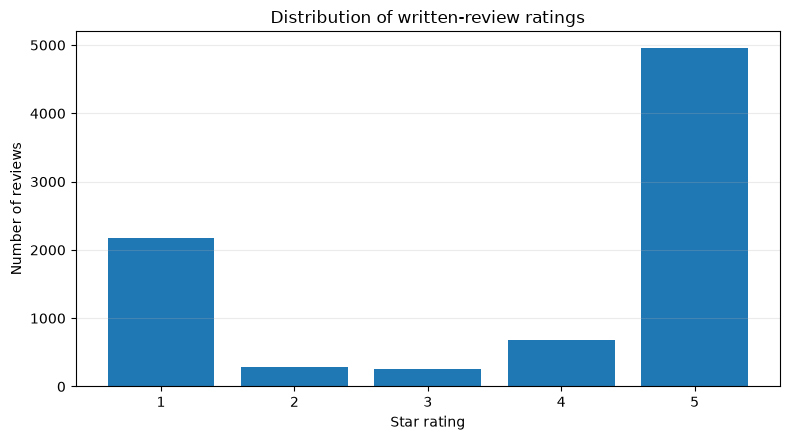

In [6]:
valid_scores = df_eda.loc[df_eda["score"].between(1, 5), "score"].dropna()
rating_summary = pd.DataFrame({
    "metric": ["Review count with valid score", "Mean", "Median", "Standard deviation", "One-star share", "One- or two-star share", "Four- or five-star share"],
    "value": [
        len(valid_scores),
        valid_scores.mean(),
        valid_scores.median(),
        valid_scores.std(),
        (valid_scores == 1).mean() * 100,
        valid_scores.isin([1, 2]).mean() * 100,
        valid_scores.isin([4, 5]).mean() * 100,
    ]
})
display(rating_summary.round(3))
rating_summary.to_csv(OUTPUT_DIR / "rating_summary.csv", index=False)

rating_counts = valid_scores.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(rating_counts.index.astype(str), rating_counts.values)
ax.set(title="Distribution of written-review ratings", xlabel="Star rating", ylabel="Number of reviews")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

rating_counts.rename_axis("score").rename("review_count").to_csv(OUTPUT_DIR / "rating_distribution.csv")

## 6. Monthly rating and review-volume trends

Monthly aggregation helps identify periods worth investigating. A month with a small number of reviews can be volatile, so always display volume alongside the mean and low-rating share.

C:\Users\Vinayak Ray\AppData\Local\Temp\ipykernel_28916\3758080562.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(monthly.tail(18).round(2))


,month_period,review_count,mean_score,median_score,one_star_count,low_rating_count,high_rating_count,one_star_pct,low_rating_pct,high_rating_pct,month
18,2025-05,257,3.80,5.0,58,73,178,22.57,28.40,69.26,2025-05
19,2025-06,301,3.56,5.0,88,100,190,29.24,33.22,63.12,2025-06
20,2025-07,293,3.78,5.0,66,76,205,22.53,25.94,69.97,2025-07
21,2025-08,240,3.67,5.0,65,73,160,27.08,30.42,66.67,2025-08
22,2025-09,205,3.52,5.0,61,68,127,29.76,33.17,61.95,2025-09
23,2025-10,297,3.79,5.0,73,80,206,24.58,26.94,69.36,2025-10
24,2025-11,160,3.69,5.0,42,48,108,26.25,30.00,67.50,2025-11
25,2025-12,196,3.84,5.0,43,54,138,21.94,27.55,70.41,2025-12
26,2026-01,211,3.77,5.0,49,60,143,23.22,28.44,67.77,2026-01
27,2026-02,207,3.74,5.0,57,62,144,27.54,29.95,69.57,2026-02


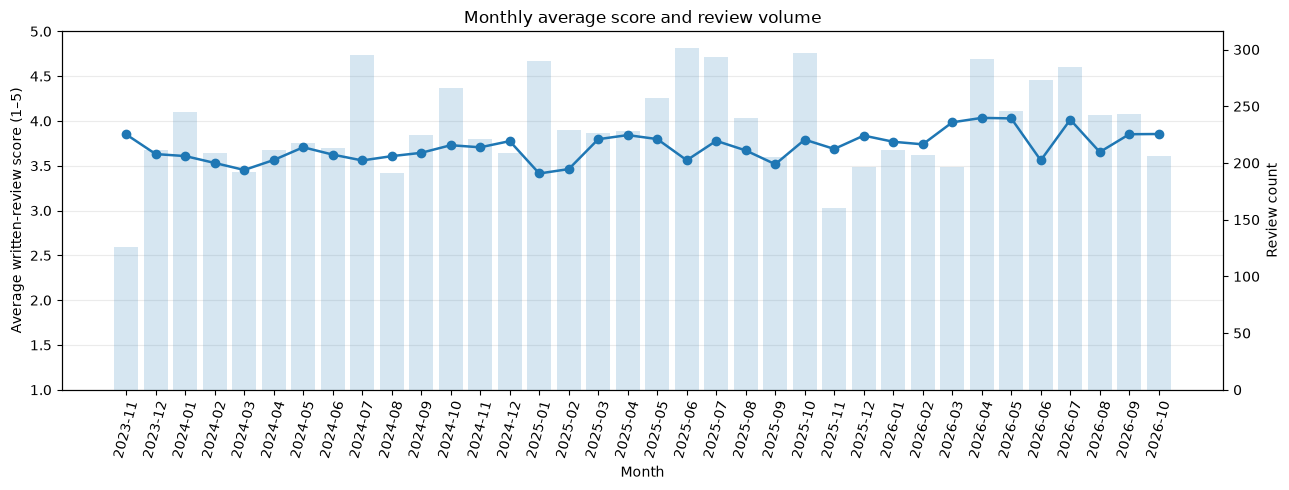

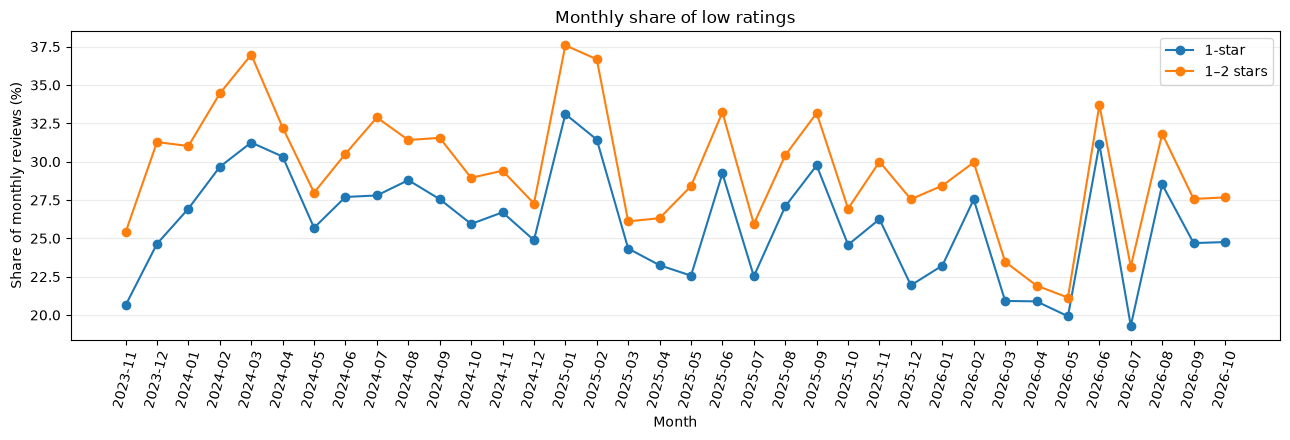

In [7]:
dated = df_eda.loc[df_eda["at"].notna() & df_eda["score"].between(1, 5)].copy()
dated["month_period"] = dated["at"].dt.tz_convert(None).dt.to_period("M")

monthly = dated.groupby("month_period").agg(
    review_count=("score", "size"),
    mean_score=("score", "mean"),
    median_score=("score", "median"),
    one_star_count=("score", lambda s: (s == 1).sum()),
    low_rating_count=("score", lambda s: s.isin([1, 2]).sum()),
    high_rating_count=("score", lambda s: s.isin([4, 5]).sum()),
).reset_index()

monthly["one_star_pct"] = monthly["one_star_count"] / monthly["review_count"] * 100
monthly["low_rating_pct"] = monthly["low_rating_count"] / monthly["review_count"] * 100
monthly["high_rating_pct"] = monthly["high_rating_count"] / monthly["review_count"] * 100
monthly["month"] = monthly["month_period"].astype(str)

display(monthly.tail(18).round(2))
monthly.to_csv(OUTPUT_DIR / "monthly_trends.csv", index=False)

fig, ax1 = plt.subplots(figsize=(13, 5))
ax1.plot(monthly["month"], monthly["mean_score"], marker="o", linewidth=1.8)
ax1.set_ylabel("Average written-review score (1–5)")
ax1.set_ylim(1, 5)
ax1.set_xlabel("Month")
ax1.tick_params(axis="x", rotation=75)
ax1.grid(axis="y", alpha=0.25)
ax2 = ax1.twinx()
ax2.bar(monthly["month"], monthly["review_count"], alpha=0.18)
ax2.set_ylabel("Review count")
ax1.set_title("Monthly average score and review volume")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(monthly["month"], monthly["one_star_pct"], marker="o", label="1-star")
ax.plot(monthly["month"], monthly["low_rating_pct"], marker="o", label="1–2 stars")
ax.set(title="Monthly share of low ratings", xlabel="Month", ylabel="Share of monthly reviews (%)")
ax.tick_params(axis="x", rotation=75)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

### Find months that merit a closer look

This is a descriptive shortlist, not an automated incident detector. Inspect review volume and the actual text before attributing a dip to a release or operational event.

In [8]:
min_monthly_volume = 20  # Change if you want a stricter minimum-volume filter.
monthly_reviewable = monthly.loc[monthly["review_count"] >= min_monthly_volume].copy()

display(
    monthly_reviewable.sort_values(["mean_score", "one_star_pct"], ascending=[True, False])
    [["month", "review_count", "mean_score", "one_star_pct", "low_rating_pct"]]
    .head(10).round(2)
)

,month,review_count,mean_score,one_star_pct,low_rating_pct
14,2025-01,290,3.41,33.10,37.59
4,2024-03,192,3.45,31.25,36.98
15,2025-02,229,3.46,31.44,36.68
22,2025-09,205,3.52,29.76,33.17
3,2024-02,209,3.53,29.67,34.45
8,2024-07,295,3.56,27.80,32.88
31,2026-06,273,3.56,31.14,33.70
19,2025-06,301,3.56,29.24,33.22
5,2024-04,211,3.56,30.33,32.23
9,2024-08,191,3.61,28.80,31.41


## 7. Rating by weekday and time

These are optional exploratory slices. Any apparent pattern may reflect who reviews and when they choose to post, rather than a change in product quality.

,weekday,review_count,mean_score,one_star_pct
0,Monday,1320,3.59,29.32
1,Tuesday,1709,3.82,23.99
2,Wednesday,1745,3.75,24.93
3,Thursday,1504,3.69,26.20
4,Friday,1148,3.75,24.65
5,Saturday,547,3.82,23.40
6,Sunday,382,3.36,35.60


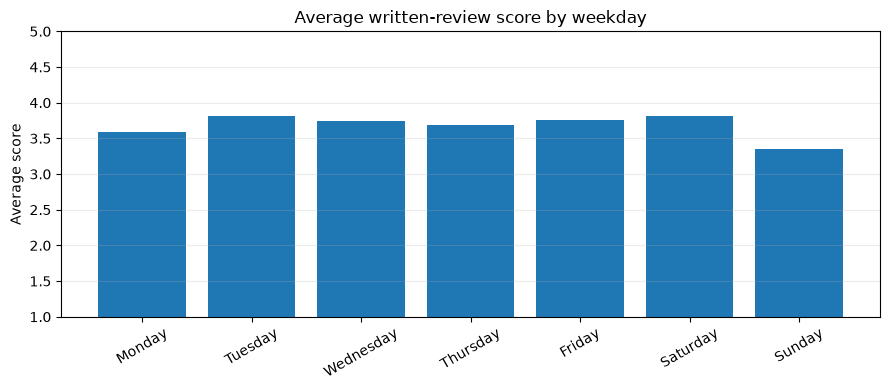

In [9]:
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_summary = (
    dated.groupby("weekday")
    .agg(review_count=("score", "size"), mean_score=("score", "mean"), one_star_pct=("score", lambda s: (s == 1).mean() * 100))
    .reindex(weekday_order)
    .reset_index()
)
display(weekday_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(weekday_summary["weekday"], weekday_summary["mean_score"])
ax.set(title="Average written-review score by weekday", xlabel="", ylabel="Average score")
ax.set_ylim(1, 5)
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 8. Developer-response analysis

Response coverage is a useful operational metric, but it does not measure whether the response solved the user's problem. Reply timing is only computed where both review and reply timestamps exist.

,metric,value
0,Reviews,8355.00
1,Reviews with developer reply,1472.00
2,Reply coverage (%),17.62
3,Replies with timestamp,1472.00
4,Median reply delay (hours),22.19
5,Median reply delay (days),0.92
6,Replies later than 7 days (%),6.82


,score,review_count,reply_count,reply_rate,reply_rate_pct
0,1,2173,422,0.19,19.42
1,2,292,60,0.21,20.55
2,3,253,53,0.21,20.95
3,4,683,138,0.20,20.20
4,5,4954,799,0.16,16.13


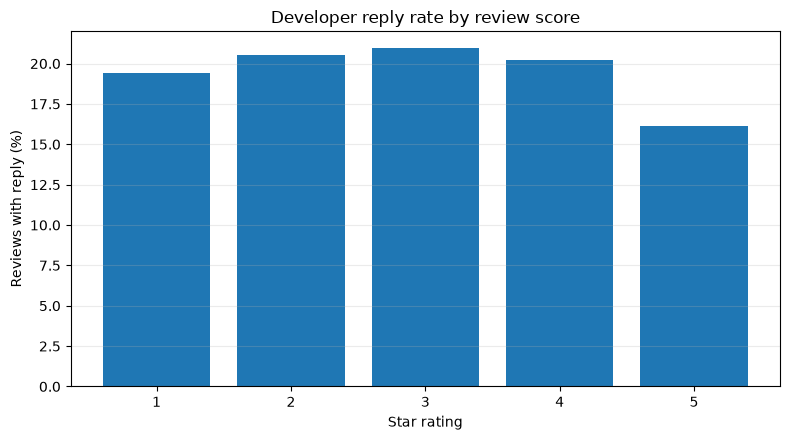

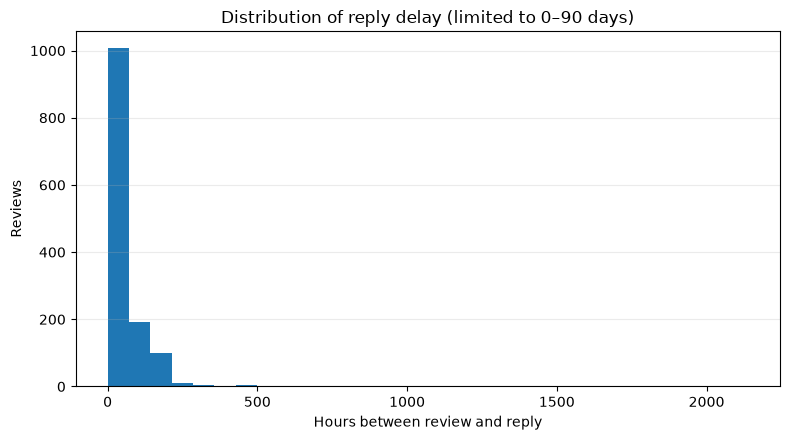

In [10]:
response_summary = pd.DataFrame({
    "metric": [
        "Reviews",
        "Reviews with developer reply",
        "Reply coverage (%)",
        "Replies with timestamp",
        "Median reply delay (hours)",
        "Median reply delay (days)",
        "Replies later than 7 days (%)",
    ],
    "value": [
        len(df_eda),
        int(df_eda["has_developer_reply"].sum()),
        df_eda["has_developer_reply"].mean() * 100,
        int((df_eda["has_developer_reply"] & df_eda["repliedAt"].notna()).sum()),
        df_eda.loc[df_eda["reply_delay_hours"].between(0, np.inf), "reply_delay_hours"].median(),
        df_eda.loc[df_eda["reply_delay_hours"].between(0, np.inf), "reply_delay_hours"].median() / 24,
        (df_eda.loc[df_eda["reply_delay_hours"].between(0, np.inf), "reply_delay_hours"] > 168).mean() * 100,
    ]
})
display(response_summary.round(2))
response_summary.to_csv(OUTPUT_DIR / "developer_response_summary.csv", index=False)

response_by_score = (
    df_eda.loc[df_eda["score"].between(1, 5)]
    .groupby("score")
    .agg(review_count=("reviewId", "size"), reply_count=("has_developer_reply", "sum"), reply_rate=("has_developer_reply", "mean"))
    .reset_index()
)
response_by_score["reply_rate_pct"] = response_by_score["reply_rate"] * 100
display(response_by_score.round(2))
response_by_score.to_csv(OUTPUT_DIR / "response_rate_by_score.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(response_by_score["score"].astype(int).astype(str), response_by_score["reply_rate_pct"])
ax.set(title="Developer reply rate by review score", xlabel="Star rating", ylabel="Reviews with reply (%)")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

reply_delays = df_eda.loc[df_eda["has_developer_reply"] & df_eda["reply_delay_hours"].between(0, 24*90), "reply_delay_hours"].dropna()
if len(reply_delays):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(reply_delays, bins=30)
    ax.set(title="Distribution of reply delay (limited to 0–90 days)", xlabel="Hours between review and reply", ylabel="Reviews")
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No usable non-negative reply delays found.")

### Are replies associated with different scores?

Compare scores of replied and unreplied reviews. This is observational and subject to selection bias: developers may be more likely to reply to certain kinds of reviews.

In [11]:
reply_score_comparison = (
    df_eda.loc[df_eda["score"].between(1, 5)]
    .groupby("has_developer_reply")
    .agg(review_count=("score", "size"), mean_score=("score", "mean"), median_score=("score", "median"), one_star_pct=("score", lambda s: (s == 1).mean() * 100))
    .reset_index()
)
reply_score_comparison["group"] = reply_score_comparison["has_developer_reply"].map({True: "Replied", False: "No reply"})
display(reply_score_comparison[["group", "review_count", "mean_score", "median_score", "one_star_pct"]].round(2))
reply_score_comparison.to_csv(OUTPUT_DIR / "score_by_reply_status.csv", index=False)

,group,review_count,mean_score,median_score,one_star_pct
0,No reply,6883,3.74,5.0,25.44
1,Replied,1472,3.57,5.0,28.67


## 9. Review length and engagement

Review length and thumbs-up counts can help identify detailed or high-engagement reviews. They should not be treated as direct measures of severity.

,score,review_count,median_words,mean_words,median_thumbs_up,reviews_with_thumbs_up
0,1,2173,11.0,17.49,0.0,209
1,2,292,15.0,20.73,0.0,22
2,3,253,15.0,20.11,0.0,10
3,4,683,3.0,9.28,0.0,23
4,5,4954,2.0,4.05,0.0,86


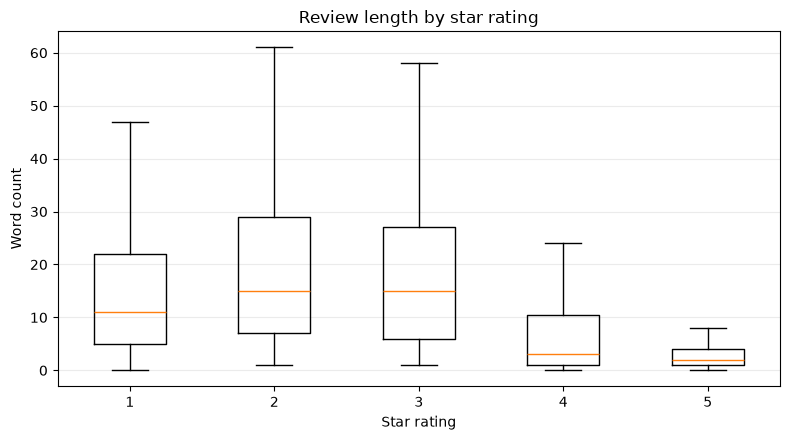

,at,score,thumbsUpCount,content,replyContent
8009,2024-01-02 12:07:02+00:00,1,63,"It is the worst app. There is no transparency about the passenger who are traveling with you, it doesn't give real-time information. It's not user friendly. There is some or th...","Hi, your organization has asked us to disable the passenger list feature. We have no option but to comply. Can you please reach out to your transport facility manager regarding..."
7903,2024-01-15 01:52:32+00:00,1,52,One of the worst app. While tracking the cab in map. It's automatically zooming out after 3 4 seconds. Have to zoom in again. It's very frustrating. Besides the tracking is not...,"Hi, sorry for the inconvenience. We'll see how we can improve the tracking experience.\nHowever, the OTPs changing is a mandate that is set by your organization. Can you please..."
4675,2025-03-19 04:15:06+00:00,5,37,It's a good app for transportation but it should be better if there is an option for a chat or call driver for the same. As sometimes due to network issues we are not able to r...,NaN
7536,2024-03-06 10:41:03+00:00,1,34,The worst app I have ever seen. The app crashes frequently in first place. When try to make booking or update details it stops working and get closed by itself. After many atte...,NaN
8169,2023-12-08 09:13:21+00:00,1,30,App is poorly developed. There are lot of technical issues. Textboxes do not support autocorrect and autocomplete so you have to type every letter and auto correct word gets er...,"Hi, sorry for the inconvenience. We are working on implementing this!\nIt shall be available in the form of a future update, do keep an eye out!"
3195,2025-09-10 16:23:22+00:00,1,27,"The app frequently crashes or hangs while booking cabs, which makes it really frustrating, especially when I’m in a hurry. The GPS tracking is unreliable—it often shows the dri...",NaN
7063,2024-05-15 21:37:12+00:00,4,25,"Very bad experience using this app. Most of the time doesn't work and gives error. Somehow if I was able to book the seat also, at the time of boarding the bus mostly doesn't o...",We apologize for the inconvenience. We request that you share your booking details at app@moveinsync.com and we will definitely look into it.
5349,2024-12-26 06:22:30+00:00,1,23,"Under Bookings ""Login and logouts"" interface are very confusing. I don't know why they have made it so complicated. Under a particular date there should be ""Login and Logout"" i...",NaN
4469,2025-04-12 05:52:54+00:00,4,21,App is very much perfect but I have a suggestion which would be helpful for all. Please provide dark mode in the app. it's very stressful to open the app during night or early ...,NaN
7445,2024-03-19 13:15:57+00:00,1,19,"It's disgusting, worst and useless app. No matter how many times the user zoom in to see the cab location, the app is designed to zoom out immediately, show the cab location an...","We understand this can be frustrating. We are working towards making this better.\nThank you for the detailed review, we will surely fix this in an upcoming update.\nPlease wri..."


In [12]:
length_summary = (
    df_eda.loc[df_eda["has_text"]]
    .groupby("score")
    .agg(
        review_count=("reviewId", "size"),
        median_words=("review_word_count", "median"),
        mean_words=("review_word_count", "mean"),
        median_thumbs_up=("thumbsUpCount", "median"),
        reviews_with_thumbs_up=("thumbsUpCount", lambda s: (s.fillna(0) > 0).sum()),
    )
    .reset_index()
)
display(length_summary.round(2))
length_summary.to_csv(OUTPUT_DIR / "review_length_engagement_by_score.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(
    [df_eda.loc[df_eda["score"] == s, "review_word_count"].dropna() for s in [1, 2, 3, 4, 5]],
    tick_labels=["1", "2", "3", "4", "5"],
    showfliers=False
)
ax.set(title="Review length by star rating", xlabel="Star rating", ylabel="Word count")
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

top_engaged = df_eda.sort_values("thumbsUpCount", ascending=False)[
    ["at", "score", "thumbsUpCount", "content", "replyContent"]
].head(15)
display(top_engaged)
top_engaged.to_csv(OUTPUT_DIR / "top_engaged_reviews.csv", index=False)

## 10. Text exploration without a classifier

The following section uses transparent keyword matching to surface recurring terms in low-rated reviews. It is intentionally a first-pass heuristic: a review may mention several issues, use synonyms, or contain a negation. Validate examples manually before using counts as findings.

,term,count
0,cab,638
1,time,609
2,experience,528
3,service,439
4,easy,385
5,use,364
6,user,358
7,location,341
8,can,315
9,driver,315


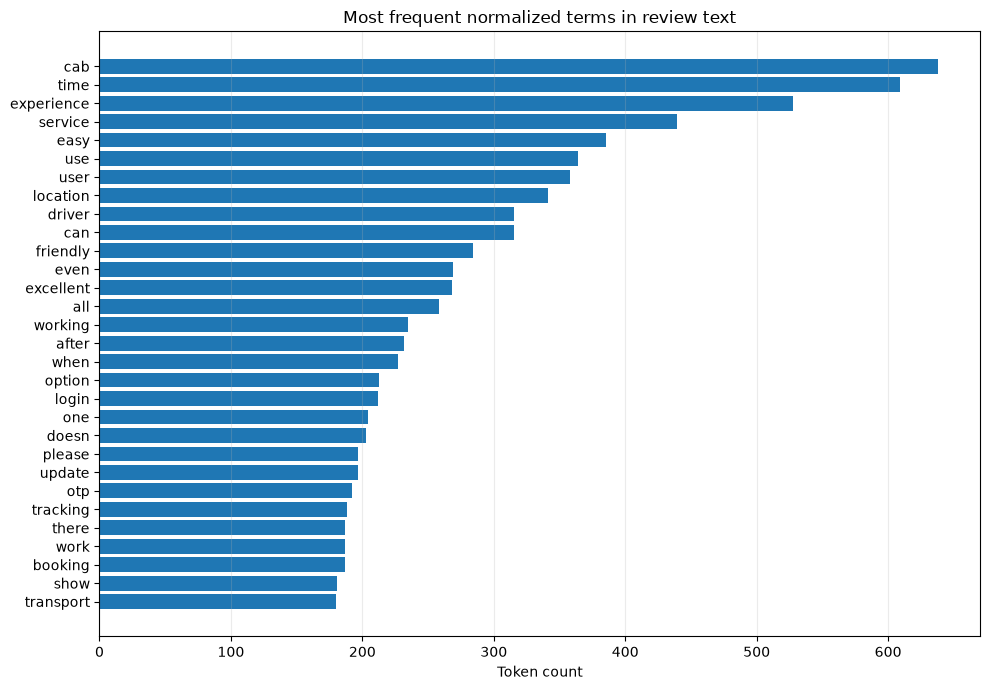

In [13]:
# Lightweight text normalization using only the Python standard library.
STOPWORDS = set('''
a an the and or but if while with to of for in on at by from is are was were be been being
it its this that these those i we you they he she them my our your their me us as am do does
did have has had not no so very really just app application good great nice best worst bad
'''.split())

def tokenize(text):
    tokens = re.findall(r"[a-z]+", str(text).lower())
    return [t for t in tokens if len(t) > 2 and t not in STOPWORDS]

text_df = df_eda.loc[df_eda["has_text"]].copy()
text_df["tokens"] = text_df["content_clean"].map(tokenize)

from collections import Counter
all_tokens = Counter(token for row in text_df["tokens"] for token in row)
top_terms = pd.DataFrame(all_tokens.most_common(30), columns=["term", "count"])
display(top_terms)
top_terms.to_csv(OUTPUT_DIR / "top_review_terms.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 7))
plot_terms = top_terms.sort_values("count", ascending=True)
ax.barh(plot_terms["term"], plot_terms["count"])
ax.set(title="Most frequent normalized terms in review text", xlabel="Token count", ylabel="")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Keyword groups for issue discovery

These keyword groups are deliberately broad and overlapping. Counts below are **reviews matching at least one keyword in a group**, not mutually exclusive categories. One review may match multiple groups, and missed synonyms are possible.

,keyword_group,reviews_matched,share_of_text_reviews_pct,one_or_two_star_matches
4,Delay / late cab,863,10.33,543
0,App access / login / crash,850,10.17,647
2,Tracking / GPS,674,8.07,368
5,Driver / safety,517,6.19,288
7,UX / usability,512,6.13,94
1,Booking / schedule,506,6.06,312
6,Support / response,196,2.35,153
3,Cab availability / no-show,88,1.05,72


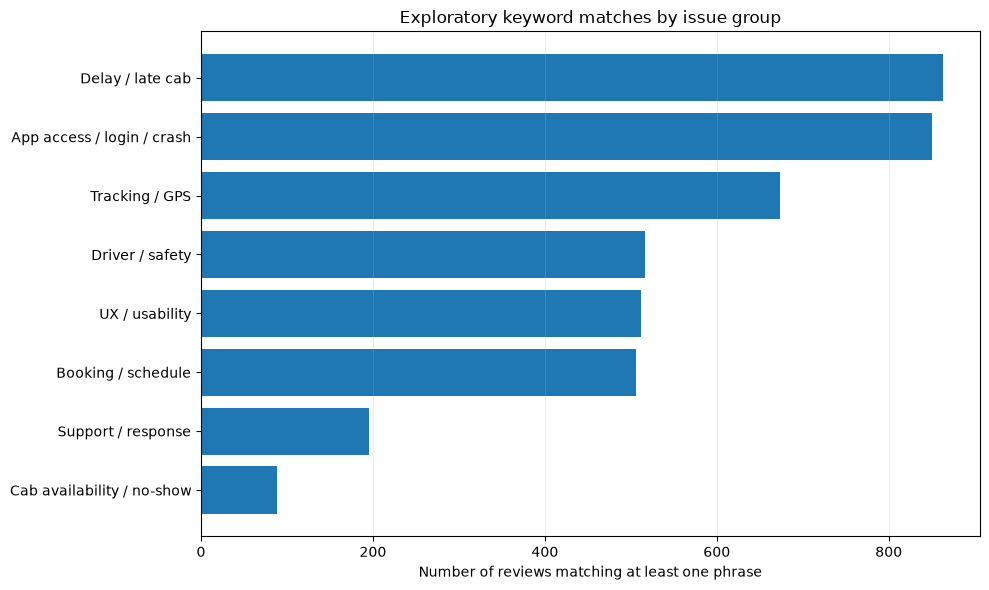

In [14]:
KEYWORD_GROUPS = {
    "App access / login / crash": [
        "login", "log in", "otp", "crash", "crashes", "crashing", "open", "loading",
        "load", "error", "stuck", "password", "signin", "sign in", "update"
    ],
    "Booking / schedule": [
        "book", "booking", "schedule", "scheduled", "cancel", "cancellation",
        "slot", "shift", "availability", "reschedule"
    ],
    "Tracking / GPS": [
        "track", "tracking", "location", "gps", "map", "live location", "route"
    ],
    "Cab availability / no-show": [
        "no cab", "cab not", "didn't come", "did not come", "no show", "noshow",
        "vehicle not", "not assigned", "unavailable"
    ],
    "Delay / late cab": [
        "late", "delay", "delayed", "waiting", "waited", "time", "arrived late"
    ],
    "Driver / safety": [
        "driver", "driving", "unsafe", "safety", "rash", "behaviour", "behavior",
        "rude", "speeding"
    ],
    "Support / response": [
        "support", "customer care", "helpdesk", "complaint", "helpline", "no response",
        "respond", "contact"
    ],
    "UX / usability": [
        "confusing", "unintuitive", "difficult to use", "hard to use", "user friendly",
        "interface", "design", "complicated", "easy to use"
    ],
}

def has_any_phrase(text, phrases):
    t = str(text).lower()
    return any(phrase in t for phrase in phrases)

for group, phrases in KEYWORD_GROUPS.items():
    text_df[group] = text_df["content_clean"].map(lambda x: has_any_phrase(x, phrases))

keyword_summary = pd.DataFrame([
    {
        "keyword_group": group,
        "reviews_matched": int(text_df[group].sum()),
        "share_of_text_reviews_pct": text_df[group].mean() * 100,
        "one_or_two_star_matches": int(text_df.loc[text_df["score"].isin([1, 2]), group].sum()),
    }
    for group in KEYWORD_GROUPS
]).sort_values("reviews_matched", ascending=False)

display(keyword_summary.round(2))
keyword_summary.to_csv(OUTPUT_DIR / "keyword_group_summary.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 6))
plot_kw = keyword_summary.sort_values("reviews_matched", ascending=True)
ax.barh(plot_kw["keyword_group"], plot_kw["reviews_matched"])
ax.set(title="Exploratory keyword matches by issue group", xlabel="Number of reviews matching at least one phrase", ylabel="")
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

### Inspect examples for each keyword group

Use these samples to see whether the heuristic is producing relevant matches. This manual inspection is a necessary step before presenting keyword counts as product insights.

In [15]:
for group in KEYWORD_GROUPS:
    matched = text_df.loc[text_df[group]].sort_values(["score", "thumbsUpCount"], ascending=[True, False])
    print(f"\n{group}: {len(matched):,} matched reviews")
    if len(matched):
        display(matched[["score", "content", "thumbsUpCount"]].head(5))


App access / login / crash: 850 matched reviews


,score,content,thumbsUpCount
7903,1,One of the worst app. While tracking the cab in map. It's automatically zooming out after 3 4 seconds. Have to zoom in again. It's very frustrating. Besides the tracking is not...,52
7536,1,The worst app I have ever seen. The app crashes frequently in first place. When try to make booking or update details it stops working and get closed by itself. After many atte...,34
8169,1,App is poorly developed. There are lot of technical issues. Textboxes do not support autocorrect and autocomplete so you have to type every letter and auto correct word gets er...,30
3195,1,"The app frequently crashes or hangs while booking cabs, which makes it really frustrating, especially when I’m in a hurry. The GPS tracking is unreliable—it often shows the dri...",27
5349,1,"Under Bookings ""Login and logouts"" interface are very confusing. I don't know why they have made it so complicated. Under a particular date there should be ""Login and Logout"" i...",23



Booking / schedule: 506 matched reviews


,score,content,thumbsUpCount
7536,1,The worst app I have ever seen. The app crashes frequently in first place. When try to make booking or update details it stops working and get closed by itself. After many atte...,34
3195,1,"The app frequently crashes or hangs while booking cabs, which makes it really frustrating, especially when I’m in a hurry. The GPS tracking is unreliable—it often shows the dri...",27
5349,1,"Under Bookings ""Login and logouts"" interface are very confusing. I don't know why they have made it so complicated. Under a particular date there should be ""Login and Logout"" i...",23
3143,1,Do you even read the comments ??? Or just Blabber !!!! On multiple occasions i have observed that the app while booking a parking slot will always show waiting for me but on th...,8
4040,1,I don't know how this app even has 4 stars when it's a VERY BADLY MADE APP. It logs you off randomly and doesn't send you the OTP. You don't know how to cancel the app. You won...,6



Tracking / GPS: 674 matched reviews


...

,score,content,thumbsUpCount
8009,1,"It is the worst app. There is no transparency about the passenger who are traveling with you, it doesn't give real-time information. It's not user friendly. There is some or th...",63
7536,1,The worst app I have ever seen. The app crashes frequently in first place. When try to make booking or update details it stops working and get closed by itself. After many atte...,34
3195,1,"The app frequently crashes or hangs while booking cabs, which makes it really frustrating, especially when I’m in a hurry. The GPS tracking is unreliable—it often shows the dri...",27
5206,1,"I had a very disappointing experience with Move In Sync. The cab was shown at a different location due to a glitch in the app, but the driver reached the correct location and l...",15
3650,1,"Could not call the bus driver at critical time, as if I click on the call button, it says like The company policy is not allowed to call. Because of this functionality, I have ...",12



Support / response: 196 matched reviews


,score,content,thumbsUpCount
8009,1,"It is the worst app. There is no transparency about the passenger who are traveling with you, it doesn't give real-time information. It's not user friendly. There is some or th...",63
8169,1,App is poorly developed. There are lot of technical issues. Textboxes do not support autocorrect and autocomplete so you have to type every letter and auto correct word gets er...,30
5206,1,"I had a very disappointing experience with Move In Sync. The cab was shown at a different location due to a glitch in the app, but the driver reached the correct location and l...",15
6521,1,Very worst app. I didn't see the tracking and distance will give more and also time tracking is also worst. Instead of this I can see other apps are working souch good. And als...,14
1980,1,"The service is extremely disappointing and unreliable. Customer support is useless—the representative who attended my call was rude, unprofessional, and did not attempt to reso...",8



UX / usability: 512 matched reviews


,score,content,thumbsUpCount
8009,1,"It is the worst app. There is no transparency about the passenger who are traveling with you, it doesn't give real-time information. It's not user friendly. There is some or th...",63
7536,1,The worst app I have ever seen. The app crashes frequently in first place. When try to make booking or update details it stops working and get closed by itself. After many atte...,34
5349,1,"Under Bookings ""Login and logouts"" interface are very confusing. I don't know why they have made it so complicated. Under a particular date there should be ""Login and Logout"" i...",23
7445,1,"It's disgusting, worst and useless app. No matter how many times the user zoom in to see the cab location, the app is designed to zoom out immediately, show the cab location an...",19
5155,1,I might give it 5 star but after the latest update this app has become so stupid. Everytime it looses my login info and then I've to reenter it. And then it shows a complete st...,8


## 11. App-version analysis

Version comparisons can reveal where to investigate, but versions differ in exposure time and may be used by different populations. Avoid declaring a release responsible for a rating change without release notes and more evidence.

,reviewCreatedVersion,review_count,mean_score,one_star_pct
15,11.4.13,575,3.61,26.78
32,11.5.17,472,3.52,30.30
26,11.4.7,289,3.70,24.22
72,12.6,285,3.81,22.81
17,11.4.22,280,3.64,27.86
43,12.1.2,258,3.57,28.68
38,11.5.5,244,3.72,25.82
39,11.5.8,222,3.71,27.03
36,11.5.21,211,3.84,23.22
22,11.4.34,181,3.86,24.31


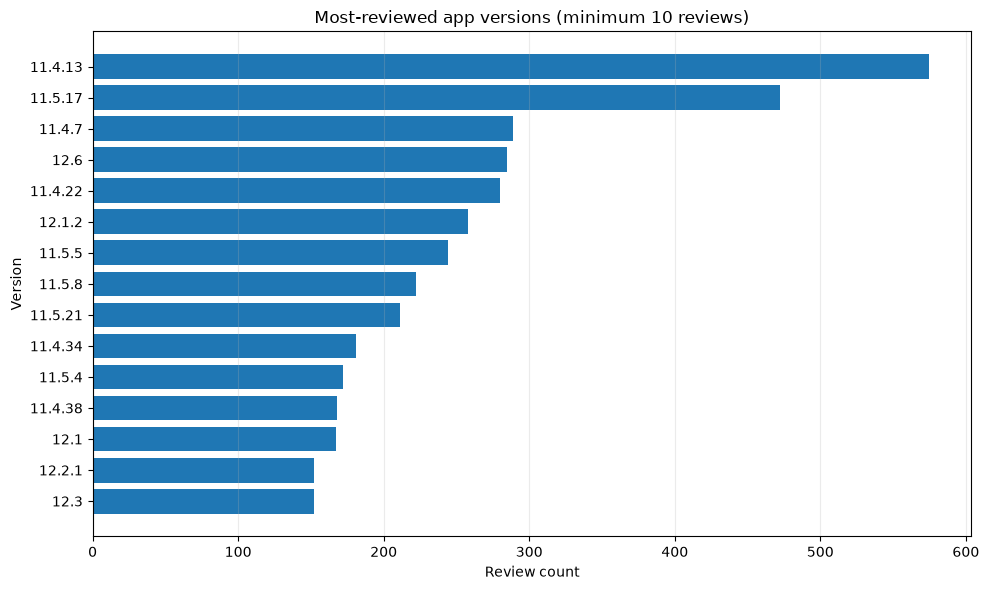

In [16]:
version_col = "reviewCreatedVersion"
version_data = df_eda.loc[df_eda[version_col].notna() & df_eda["score"].between(1, 5)].copy()
version_summary = (
    version_data.groupby(version_col)
    .agg(review_count=("score", "size"), mean_score=("score", "mean"), one_star_pct=("score", lambda s: (s == 1).mean() * 100))
    .reset_index()
)
version_summary = version_summary.loc[version_summary["review_count"] >= 10].sort_values("review_count", ascending=False)

display(version_summary.head(25).round(2))
version_summary.to_csv(OUTPUT_DIR / "version_summary_min10.csv", index=False)

if len(version_summary):
    top_versions = version_summary.head(15).sort_values("review_count", ascending=True)
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(top_versions[version_col].astype(str), top_versions["review_count"])
    ax.set(title="Most-reviewed app versions (minimum 10 reviews)", xlabel="Review count", ylabel="Version")
    ax.grid(axis="x", alpha=0.25)
    plt.tight_layout()
    plt.show()

## 12. Rating snapshot versus written-review ratings

If the snapshot file exists, compare the app-level metadata with the scraped written-review distribution. These are different metrics with different denominators and should be labeled clearly in the final case study.

In [17]:
if SNAPSHOT_PATH is not None:
    snapshots = pd.read_csv(SNAPSHOT_PATH)
    display(snapshots)

    employee_snapshot = snapshots.loc[snapshots["app_name"].astype(str).str.lower().eq("employee")]
    if len(employee_snapshot):
        snap = employee_snapshot.iloc[0]
        print(f"Employee app snapshot date: {snap.get('date')}")
        print(f"Displayed app score in snapshot: {snap.get('score')}")
        print(f"Number of app ratings in snapshot: {snap.get('ratings'):,}")
        print(f"Number of app reviews in snapshot: {snap.get('reviews'):,}")
        print(f"Average score among scraped written reviews: {valid_scores.mean():.3f}")
        print("Do not describe these two scores as the same metric.")
else:
    print("rating_snapshots.csv not found; skipping this optional comparison.")

,date,app_name,score,ratings,reviews,version,updated,star1,star2,star3,star4,star5
0,2026-10-29,driver,3.701754,57,8,Varies with device,NaN,15,1,3,5,33
1,2026-10-29,employee,4.639854,115586,23734,12.20.0,1.792654e+09,7404,867,1198,7001,99109


Employee app snapshot date: 2026-10-29
Displayed app score in snapshot: 4.6398535
Number of app ratings in snapshot: 115,586
Number of app reviews in snapshot: 23,734
Average score among scraped written reviews: 3.713
Do not describe these two scores as the same metric.


## 13. Optional: bring in the AI-classified pilot

This section is separate from the full-dataset EDA. It summarizes the labels currently present in `reviews_classified.csv`, checks joins against the raw dataset, and compares labels with star ratings. If the pilot is only 100 recent rows, explicitly call it a **date-ordered pilot**, not a representative sample.

If you have both a current and recovered output, keep them as separate versions and do not silently combine conflicting labels.

In [18]:
if CLASSIFIED_PATH is not None:
    classified = pd.read_csv(CLASSIFIED_PATH)
    print(f"Classified file: {CLASSIFIED_PATH}")
    print(f"Rows: {len(classified):,}")
    display(classified.head())

    required_cols = {"reviewId", "primary"}
    if required_cols.issubset(classified.columns):
        print("Unique classified IDs:", classified["reviewId"].nunique())
        print("Duplicate classified IDs:", classified["reviewId"].duplicated().sum())
        print("IDs not found in raw dataset:", (~classified["reviewId"].isin(df_eda["reviewId"])).sum())

        display(classified["primary"].fillna("MISSING").value_counts().rename_axis("primary").to_frame("count"))

        if "score" in classified.columns:
            ctab = pd.crosstab(classified["primary"].fillna("MISSING"), classified["score"], normalize="index") * 100
            display(ctab.round(1))

        if "owner" in classified.columns:
            display(pd.crosstab(classified["primary"].fillna("MISSING"), classified["owner"].fillna("MISSING")))

        classified.to_csv(OUTPUT_DIR / "classified_pilot_copy.csv", index=False)
    else:
        print("Expected columns reviewId and primary are missing; skip classification summaries.")
else:
    print("No reviews_classified.csv found. Put it beside this notebook to run the optional section.")

Classified file: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\reviews_classified.csv
Rows: 100


,reviewId,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion,app_name,scraped_at,primary,secondary,owner,severity,issue
0,142c2c28-d9ae-42a9-84d4-82420154c383,Convenient and User Friendly,5,0,12.20.0,2026-10-28 18:39:45,NaN,NaN,12.20.0,employee,2026-10-29 19:23:18.820742,PRAISE,NaN,none,1,NaN
1,db05df3c-4d0c-46ee-8adc-cc6d438df059,nice app,5,0,NaN,2026-10-28 15:43:15,NaN,NaN,NaN,employee,2026-10-29 19:23:18.820742,PRAISE,NaN,none,1,NaN
2,60728282-1e36-4f82-a85f-5963dce6d2fd,its was okay nice using this app,5,0,12.21.0,2026-10-28 14:32:16,NaN,NaN,12.21.0,employee,2026-10-29 19:23:18.820742,PRAISE,NaN,none,1,NaN
3,5b229fff-c2ad-4ae2-a678-06ba9f982450,simply 👌,5,0,12.20.0,2026-10-28 14:18:21,NaN,NaN,12.20.0,employee,2026-10-29 19:23:18.820742,PRAISE,NaN,none,1,NaN
4,6f676cae-5eda-4612-aefd-ca28f3507214,OTP not received.,1,0,NaN,2026-10-28 10:58:55,NaN,NaN,NaN,employee,2026-10-29 19:23:18.820742,APP_ACCESS,NaN,app,3,OTP not received


Unique classified IDs: 100
Duplicate classified IDs: 0
IDs not found in raw dataset: 0


,count
primary,
PRAISE,66
APP_ACCESS,7
UNCLEAR,5
BOOKING,4
UX_CHANGE,4
TRACKING,3
DRIVER,3
SUPPORT,2
POOLING,2


score,1,2,3,4,5
primary,,,,,
APP_ACCESS,85.7,14.3,0.0,0.0,0.0
BOOKING,25.0,50.0,0.0,25.0,0.0
DRIVER,100.0,0.0,0.0,0.0,0.0
LATE_CAB,100.0,0.0,0.0,0.0,0.0
NO_CAB,100.0,0.0,0.0,0.0,0.0
OTHER_PRODUCT,0.0,0.0,100.0,0.0,0.0
POOLING,100.0,0.0,0.0,0.0,0.0
PRAISE,0.0,0.0,0.0,0.0,100.0
SAFETY,0.0,0.0,0.0,0.0,100.0


owner,app,client_company,none,ops_vendor
primary,,,,
APP_ACCESS,7,0,0,0
BOOKING,3,1,0,0
DRIVER,0,0,0,3
LATE_CAB,0,0,0,1
NO_CAB,0,0,0,1
OTHER_PRODUCT,1,0,0,0
POOLING,0,2,0,0
PRAISE,0,0,66,0
SAFETY,1,0,0,0


## 14. Export a compact set of tables for the case study

The notebook already exports the key tables during each section. This final cell creates a quick index of exported files.

In [19]:
exported_files = sorted(OUTPUT_DIR.glob("*.csv"))
display(pd.DataFrame({
    "file": [p.name for p in exported_files],
    "size_kb": [round(p.stat().st_size / 1024, 1) for p in exported_files],
}))
print(f"\nSaved {len(exported_files)} CSV outputs to: {OUTPUT_DIR.resolve()}")

,file,size_kb
0,classified_pilot_copy.csv,20.3
1,data_quality_summary.csv,0.3
2,developer_response_summary.csv,0.3
3,keyword_group_summary.csv,0.4
4,monthly_trends.csv,3.9
5,rating_distribution.csv,0.1
6,rating_summary.csv,0.2
7,response_rate_by_score.csv,0.3
8,review_length_engagement_by_score.csv,0.3
9,score_by_reply_status.csv,0.2



Saved 13 CSV outputs to: C:\Users\Vinayak Ray\Downloads\MoveInSync\data\outputs


## 15. Reporting checklist

Before turning these results into slides or a report:

1. State the dataset size, date range, source, and extraction date.
2. Separate the app's displayed Play Store score from the mean of scraped written reviews.
3. Show monthly review volume alongside monthly average score and low-rating share.
4. Treat keyword counts as exploratory and validate representative review examples.
5. Report developer-response coverage separately from response quality or resolution.
6. Do not infer causality from monthly dips, app versions, or response status.
7. If using the AI classifier, disclose the pilot size, sampling method, model/tool used, taxonomy, manual validation approach, and limitations.
8. Do not extrapolate the first 100 date-ordered classified reviews to all 8,355 reviews.
9. Distinguish observed facts from hypotheses and recommendations.
10. Save the notebook and CSV exports with the final deliverable for reproducibility.